In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Part 1. Data Selection

The trading date that was selected was , as it has at least three calendar days remaining until expiration.

We then used Python to examine the stock price, time to expiration, interest rates, and available exercise prices. We also plotted the observed call options price against exercise prices, and then removed any unreliable observations, such as those with a higher ask than bid, for example.

Trading Date: 2025-03-03
Expiration Date: 2025-03-07
Calendar Days to Expiration: 4
Stock Price: $43.795
Interest Rate: 0.046861 (4.686%)
Dividend Yield: 0.019023 (1.902%)
Time to Expiration: 0.014116 years
Available Exercise Prices: [25.0, 29.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 35.5, 36.0, 36.5, 37.0, 37.5, 38.0, 38.5, 39.0, 39.5, 40.0, 40.5, 41.0, 41.5, 42.0, 42.5, 43.0, 43.5, 44.0, 44.5, 45.0, 45.5, 46.0, 46.5, 47.0, 47.5, 48.0, 48.5, 49.0, 49.5, 50.0, 51.0, 52.0, 53.0, 55.0]

Total call options: 42
Retained observations: 21
Excluded observations: 21

Retained options:
 okey_xx  bidPrc  askPrc  mid_price  spread  relative_spread  openInterest
    25.0   18.60   18.95     18.775    0.35         0.018642             5
    29.0   14.65   14.95     14.800    0.30         0.020270             2
    34.0    9.65    9.95      9.800    0.30         0.030612             1
    35.0    8.65    8.90      8.775    0.25         0.028490            12
    35.5    8.20    8.45      8.325    0.25

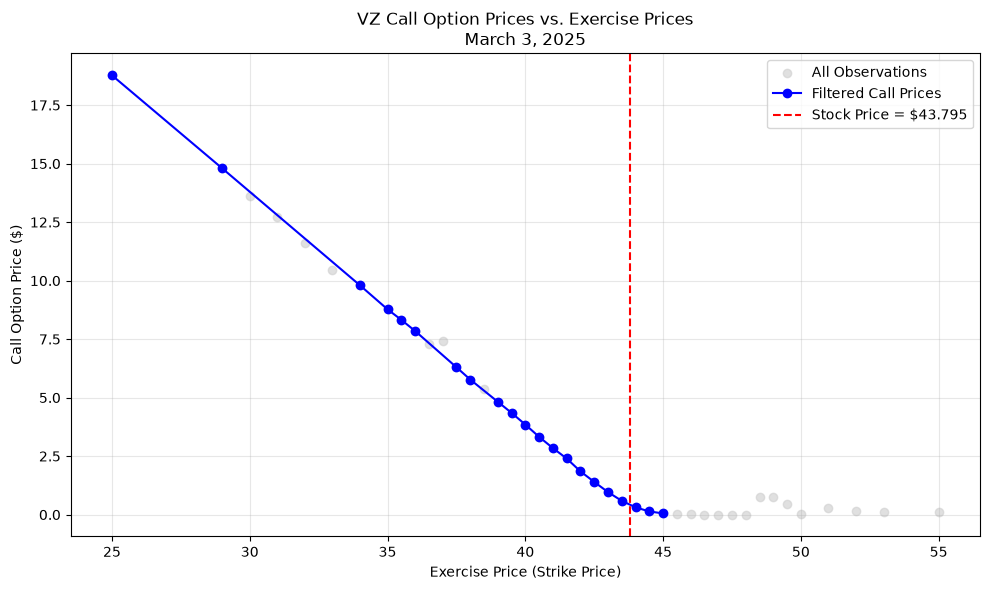

In [20]:
# 1. Load the dataset
df = pd.read_csv("VZ.csv")

df["tradingDate"] = pd.to_datetime(df["tradingDate"])
df["okey_date"] = pd.to_datetime(df["okey_date"])

# 2. Select trading date, expiration, and call options
trading_date = pd.Timestamp("2025-03-03")
expiration_date = pd.Timestamp("2025-03-07")

calls = df[
    (df["tradingDate"] == trading_date) &
    (df["okey_date"] == expiration_date) &
    (df["okey_cp"] == "Call")
].copy()

if calls.empty:
    raise ValueError("No matching call options found.")

# 3. Identify key variables
stock_price = calls["uClose"].iloc[0]
interest_rate = calls["rate"].iloc[0]
dividend_yield = calls["sdiv"].iloc[0]
time_to_expiration = calls["years"].iloc[0]
calendar_days = (expiration_date - trading_date).days
strikes = sorted(calls["okey_xx"].unique())

assert calendar_days >= 3

print("Trading Date:", trading_date.date())
print("Expiration Date:", expiration_date.date())
print("Calendar Days to Expiration:", calendar_days)
print(f"Stock Price: ${stock_price:.3f}")
print(f"Interest Rate: {interest_rate:.6f} ({interest_rate:.3%})")
print(f"Dividend Yield: {dividend_yield:.6f} ({dividend_yield:.3%})")
print(f"Time to Expiration: {time_to_expiration:.6f} years")
print("Available Exercise Prices:", [float(x) for x in strikes])

# 4. Calculate mid-prices and bid-ask spreads
calls["mid_price"] = (
    calls["bidPrc"] + calls["askPrc"]
) / 2

calls["spread"] = calls["askPrc"] - calls["bidPrc"]

calls["relative_spread"] = np.where(
    calls["mid_price"] > 0,
    calls["spread"] / calls["mid_price"],
    np.inf
)

# 5. Filter unreliable observations
# Require:
# - Positive bid
# - Ask >= bid
# - Absolute spread <= $0.50
# - Relative spread <= 25%
# - Positive open interest

valid = (
    (calls["bidPrc"] > 0) &
    (calls["askPrc"] >= calls["bidPrc"]) &
    (calls["spread"] <= 0.50) &
    (calls["relative_spread"] <= 0.25) &
    (calls["openInterest"] > 0)
)

clean_calls = calls[valid].copy()
excluded_calls = calls[~valid].copy()

clean_calls = clean_calls.sort_values("okey_xx")

# 6. Print results
print("\nTotal call options:", len(calls))
print("Retained observations:", len(clean_calls))
print("Excluded observations:", len(excluded_calls))

print("\nRetained options:")
print(clean_calls[
    ["okey_xx", "bidPrc", "askPrc",
     "mid_price", "spread", "relative_spread",
     "openInterest"]
].to_string(index=False))

print("\nExcluded options:")
print(excluded_calls[
    ["okey_xx", "bidPrc", "askPrc",
     "spread", "relative_spread", "openInterest"]
].to_string(index=False))

# 7. Plot observed call prices against strike prices
plt.figure(figsize=(10, 6))

plt.scatter(
    calls["okey_xx"],
    calls["mid_price"],
    color="lightgray",
    label="All Observations",
    alpha=0.7
)

plt.plot(
    clean_calls["okey_xx"],
    clean_calls["mid_price"],
    "o-",
    color="blue",
    label="Filtered Call Prices"
)

plt.axvline(
    stock_price,
    color="red",
    linestyle="--",
    label=f"Stock Price = ${stock_price:.3f}"
)

plt.xlabel("Exercise Price (Strike Price)")
plt.ylabel("Call Option Price ($)")
plt.title("VZ Call Option Prices vs. Exercise Prices\nMarch 3, 2025")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Part 2. Estimating the Lognormal Distribution


# Part 2: Derivation of the Expected European Call Payoff

Assume the terminal stock price $S_T$ follows a lognormal distribution:

$$
\ln S_T \sim N(\mu,\sigma^2), \qquad \sigma>0.
$$

Let $K$ denote the exercise (strike) price. The payoff of a European call at expiration is

$$
(S_T-K)^+ = \max(S_T-K,0).
$$

## Step 1: Express the expected payoff

A call has a positive payoff only when $S_T>K$, so

$$
\begin{aligned}
\mathbb E[(S_T-K)^+]
&=\mathbb E[(S_T-K)\mathbf 1_{\{S_T>K\}}]\\
&=\mathbb E[S_T\mathbf 1_{\{S_T>K\}}]
-K\Pr(S_T>K).
\end{aligned}
$$

Write $Y=\ln S_T$. Then $Y\sim N(\mu,\sigma^2)$, $S_T=e^Y$, and $S_T>K$ if and only if $Y>\ln K$.

## Step 2: Calculate the probability of exercise

Standardizing the normal variable gives

$$
\begin{aligned}
\Pr(S_T>K)
&=\Pr(Y>\ln K)\\
&=1-\Phi\left(\frac{\ln K-\mu}{\sigma}\right)\\
&=\Phi\left(\frac{\mu-\ln K}{\sigma}\right),
\end{aligned}
$$

where $\Phi$ is the standard normal cumulative distribution function. Define

$$
d_2=\frac{\mu-\ln K}{\sigma}.
$$

Thus, $\Pr(S_T>K)=\Phi(d_2)$.

## Step 3: Calculate the expected stock price conditional on exercise (without normalizing)

Using the normal density of $Y$,

$$
\mathbb E[S_T\mathbf 1_{\{S_T>K\}}]
=\int_{\ln K}^{\infty} e^y\frac{1}{\sigma\sqrt{2\pi}}
\exp\left(-\frac{(y-\mu)^2}{2\sigma^2}\right)\,dy.
$$

Complete the square in the exponent:

$$
y-\frac{(y-\mu)^2}{2\sigma^2}
=\mu+\frac{\sigma^2}{2}
-\frac{(y-\mu-\sigma^2)^2}{2\sigma^2}.
$$

Substituting this identity into the integral,

$$
\begin{aligned}
\mathbb E[S_T\mathbf 1_{\{S_T>K\}}]
&=e^{\mu+\sigma^2/2}\int_{\ln K}^{\infty}
\frac{1}{\sigma\sqrt{2\pi}}
\exp\left(-\frac{(y-\mu-\sigma^2)^2}{2\sigma^2}\right)\,dy\\
&=e^{\mu+\sigma^2/2}
\Phi\left(\frac{\mu+\sigma^2-\ln K}{\sigma}\right).
\end{aligned}
$$

Define

$$
d_1=\frac{\mu+\sigma^2-\ln K}{\sigma}=d_2+\sigma.
$$

Therefore,

$$
\mathbb E[S_T\mathbf 1_{\{S_T>K\}}]
=e^{\mu+\sigma^2/2}\Phi(d_1).
$$

## Step 4: Combine the two terms

Substituting the results from Steps 2 and 3 into Step 1 yields the **expected call payoff**:

$$
\boxed{\mathbb E[(S_T-K)^+]
=e^{\mu+\sigma^2/2}\Phi(d_1)-K\Phi(d_2)}.
$$

If the distribution is a **risk-neutral distribution** and $r$ is the continuously compounded annual risk-free interest rate, the **call price today** is the discounted expected payoff:

$$
\boxed{C(K)=e^{-rT}\left[e^{\mu+\sigma^2/2}\Phi(d_1)-K\Phi(d_2)\right]}.
$$

Here, $T$ is the time to expiration in years.


In [21]:
from scipy.optimize import minimize_scalar
from scipy.stats import norm, lognorm

# Use the cleaned observations from Part 1
S0 = float(clean_calls["uClose"].iloc[0])
r = float(clean_calls["rate"].iloc[0])
q = float(clean_calls["sdiv"].iloc[0])
T = float(clean_calls["years"].iloc[0])

K = clean_calls["okey_xx"].to_numpy()
observed = clean_calls["mid_price"].to_numpy()

# Risk-neutral expected terminal stock price
expected_ST = S0 * np.exp((r - q) * T)

# Theoretical European call price
def call_price(K, mu, sigma):
    d1 = (mu + sigma**2 - np.log(K)) / sigma
    d2 = (mu - np.log(K)) / sigma

    return np.exp(-r * T) * (
        np.exp(mu + sigma**2 / 2) * norm.cdf(d1)
        - K * norm.cdf(d2)
    )

# Estimate sigma while imposing the forward-price condition
def objective(sigma):
    mu = np.log(expected_ST) - sigma**2 / 2
    theoretical = call_price(K, mu, sigma)
    return np.sum((theoretical - observed)**2)

result = minimize_scalar(
    objective,
    bounds=(0.000001, 0.30),
    method="bounded"
)

sigma_hat = float(result.x)
mu_hat = float(np.log(expected_ST) - sigma_hat**2 / 2)

print(f"Estimated Mu: {mu_hat:.6f}")
print(f"Estimated Sigma: {sigma_hat:.6f}")

Estimated Mu: 3.779627
Estimated Sigma: 0.023891


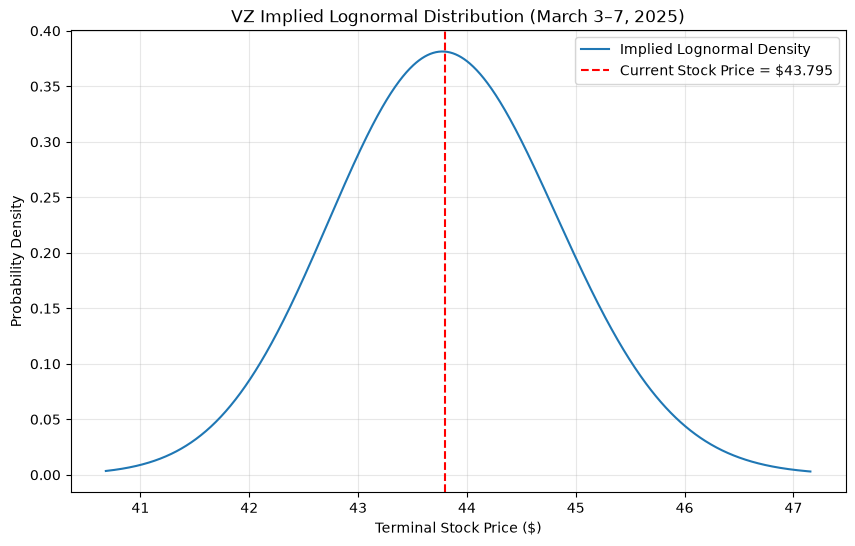

In [22]:
# Construct the fitted lognormal distribution
distribution = lognorm(s=sigma_hat, scale=np.exp(mu_hat))

prices = np.linspace(
    distribution.ppf(0.001),
    distribution.ppf(0.999),
    1000
)

density = distribution.pdf(prices)

plt.figure(figsize=(10, 6))

plt.plot(prices, density, label="Implied Lognormal Density")

plt.axvline(
    S0,
    color="red",
    linestyle="--",
    label=f"Current Stock Price = ${S0:.3f}"
)

plt.xlabel("Terminal Stock Price ($)")
plt.ylabel("Probability Density")
plt.title("VZ Implied Lognormal Distribution (March 3–7, 2025)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [23]:
# Mean of the terminal stock price
mean_ST = np.exp(mu_hat + sigma_hat**2 / 2)

# Standard deviation of the terminal stock price
std_ST = np.sqrt(
    (np.exp(sigma_hat**2) - 1)
    * np.exp(2 * mu_hat + sigma_hat**2)
)

# Probability of finishing below the current stock price
prob_below = norm.cdf(
    (np.log(S0) - mu_hat) / sigma_hat
)

print(f"Mean: ${mean_ST:.4f}")
print(f"Standard Deviation: ${std_ST:.4f}")
print(f"P(S_T < S0): {prob_below:.2%}")

Mean: $43.8122
Standard Deviation: $1.0469
P(S_T < S0): 49.82%
